# Extension B2: Watching an experiment while it runs

Experiments run for days or weeks, and everyone wants to look at the results along the way. Looking is harmless. **Acting** on what you see, stopping as soon as the result looks significant, is not. This lesson uses simulation to show:

1. **A/A tests:** what "no effect" looks like, and why 5% of tests come out "significant" anyway.
2. **Peeking:** checking daily and stopping at the first p < 0.05 inflates false positives several times over.
3. **Sequential testing:** a design that allows daily looks at an honest error rate, and still stops early when the effect is real.
4. **Bayesian monitoring:** why "stop when the probability of being better passes 95%" has the same problem.

Setting: the coupon experiment from extension B1, with a two-week run, about 14,300 users per arm arriving each day, and a 4.86% order rate without coupon. Each scenario is simulated 10,000 times.

The percentages below come from random simulations. With a different version of numpy the random draws differ, so your numbers may differ by a few tenths of a percentage point (with 10,000 simulations, that is ordinary noise). The conclusions do not change.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from expt.plotting import BAND, INK, INK_2, SERIES, new_figure, style_axes
from expt.sequential import apply_rule, calibrate_obf, obf_boundaries, simulate_daily_paths

P_CONTROL = 0.0486
USERS_PER_DAY = 200_000 // 14
DAYS = 14
N_SIMS = 10_000
Z = stats.norm.ppf(0.975)

aa = simulate_daily_paths(P_CONTROL, P_CONTROL, USERS_PER_DAY, DAYS, N_SIMS, seed=10)

## 1. A/A tests: what no effect looks like

An **A/A test** splits users into two groups that get exactly the same thing. Running them is a standard way to check an experimentation system: if the split, the logging or the statistics are broken, A/A tests reveal it.

Analysed once at the end, the p-values of 10,000 A/A tests should be spread evenly between 0 and 1, so about 5% fall below 0.05 by pure chance:

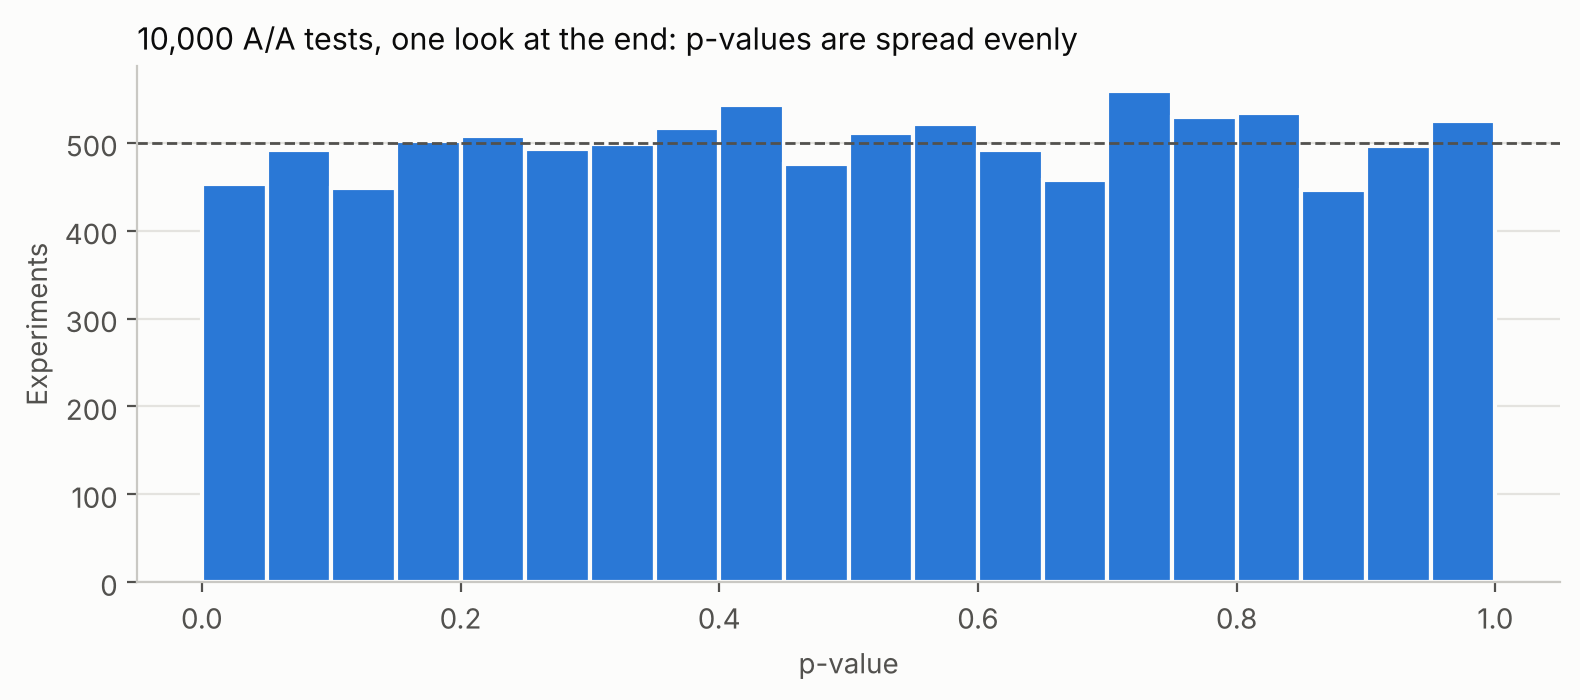

Share with p < 0.05: 4.5%


In [2]:
# figure: aa_pvalues
p_final = 2 * stats.norm.sf(np.abs(aa.z[:, -1]))
fig, ax = new_figure(8, 3.6)
ax.hist(p_final, bins=20, color=SERIES[0], edgecolor="#fcfcfb", linewidth=1.5)
ax.axhline(N_SIMS / 20, color=INK_2, linewidth=1, linestyle="--")
style_axes(ax, title="10,000 A/A tests, one look at the end: p-values are spread evenly",
           xlabel="p-value", ylabel="Experiments")
plt.tight_layout()
plt.show()
print(f"Share with p < 0.05: {(p_final < 0.05).mean():.1%}")

That 5% is the false-positive rate we signed up for. A real A/A test that showed, say, 15% would point to a broken system.

## 2. Peeking

Now do what happens in practice: look at the dashboard every day, and stop the first day p < 0.05.

False positives with daily peeking: 22% (instead of 5%)


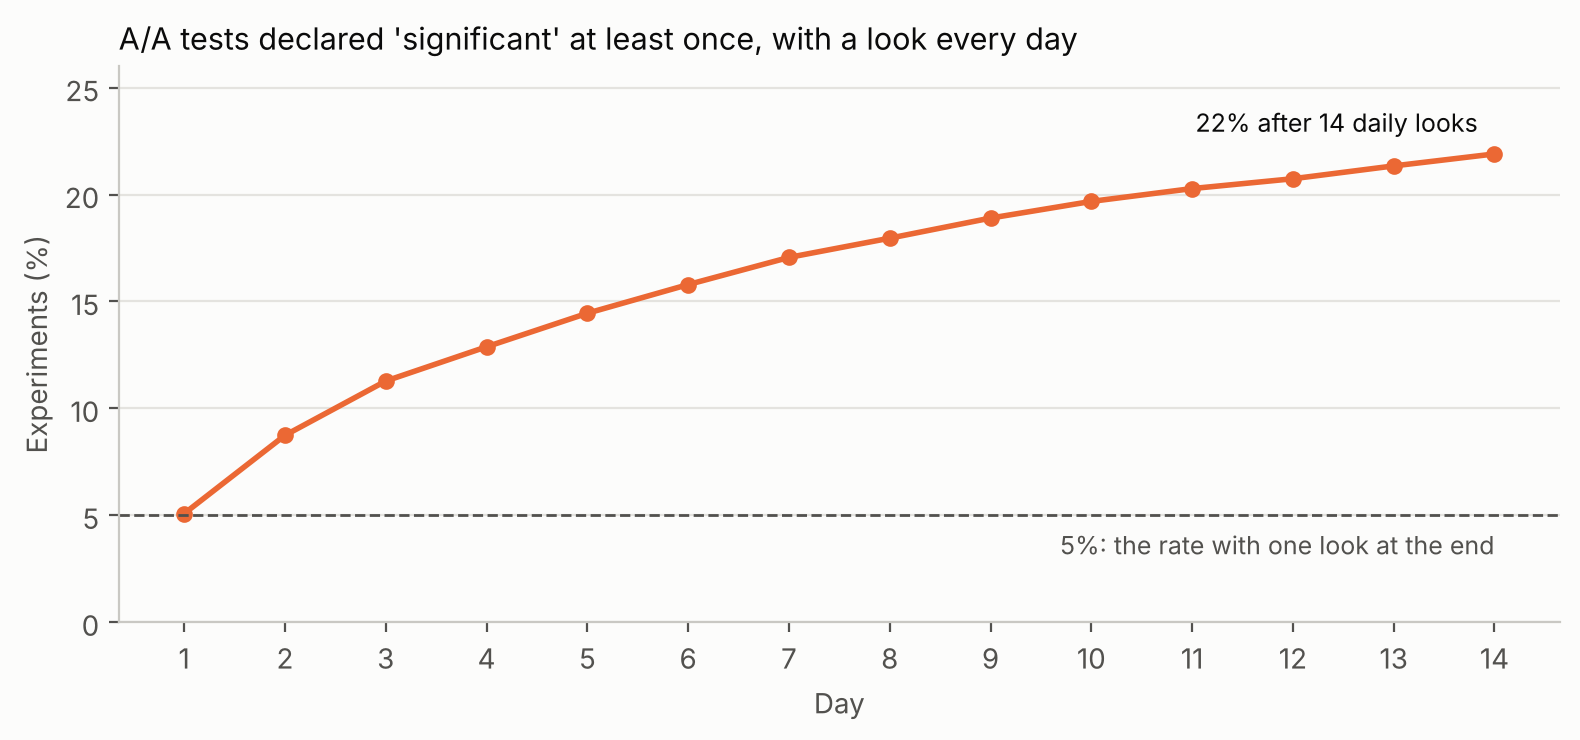

In [3]:
# figure: peeking
peeking = apply_rule(aa.z, lambda z: np.abs(z) > Z)
print(f"False positives with daily peeking: {peeking.share_stopped:.0%} (instead of 5%)")

crossed_by_day = (np.abs(aa.z) > Z).cumsum(axis=1).astype(bool).mean(axis=0)
fig, ax = new_figure(8, 3.8)
days = np.arange(1, DAYS + 1)
ax.plot(days, crossed_by_day * 100, color=SERIES[1], linewidth=2, marker="o", markersize=5)
ax.axhline(5, color=INK_2, linewidth=1, linestyle="--")
ax.annotate("5%: the rate with one look at the end", (DAYS, 5), xytext=(0, -14), textcoords="offset points",
            ha="right", color=INK_2, fontsize=9)
ax.annotate(f"{crossed_by_day[-1]:.0%} after 14 daily looks", (DAYS, crossed_by_day[-1] * 100), xytext=(-6, 8),
            textcoords="offset points", ha="right", color=INK, fontsize=9)
ax.set_xticks(days)
ax.set_ylim(0, 26)
style_axes(ax, title="A/A tests declared 'significant' at least once, with a look every day",
           xlabel="Day", ylabel="Experiments (%)")
plt.tight_layout()
plt.show()

Each daily look is another chance for random noise to cross the line, and once it does, the experiment stops there. With 14 looks, more than one in five experiments with **no effect at all** would be declared a winner. A company running dozens of tests a year this way ships many changes that do nothing.

## 3. A sequential design: looking honestly

The fix is to make the bar higher at each look, so that the total chance of a false positive over all looks is 5%. **O'Brien–Fleming** boundaries are the classic choice: very strict early (when data is scarce), close to the usual 1.96 by the end. We calibrate them by simulation for 14 daily looks:

In [4]:
c = calibrate_obf(DAYS, alpha=0.05, n_sims=50_000, seed=11)
bounds = obf_boundaries(DAYS, c)
pd.DataFrame({"day": days, "|z| needed to stop": bounds, "equivalent p-value": 2 * stats.norm.sf(bounds)}).set_index("day").T.round(4)

day,1,2,3,4,5,6,7,8,9,10,11,12,13,14
|z| needed to stop,7.8148,5.5259,4.5119,3.9074,3.4949,3.1904,2.9537,2.7629,2.6049,2.4713,2.3563,2.2559,2.1674,2.0886
equivalent p-value,0.0000,0.0000,0.0000,0.0001,0.0005,0.0014,0.0031,0.0057,0.0092,0.0135,0.0185,0.0241,0.0302,0.0367


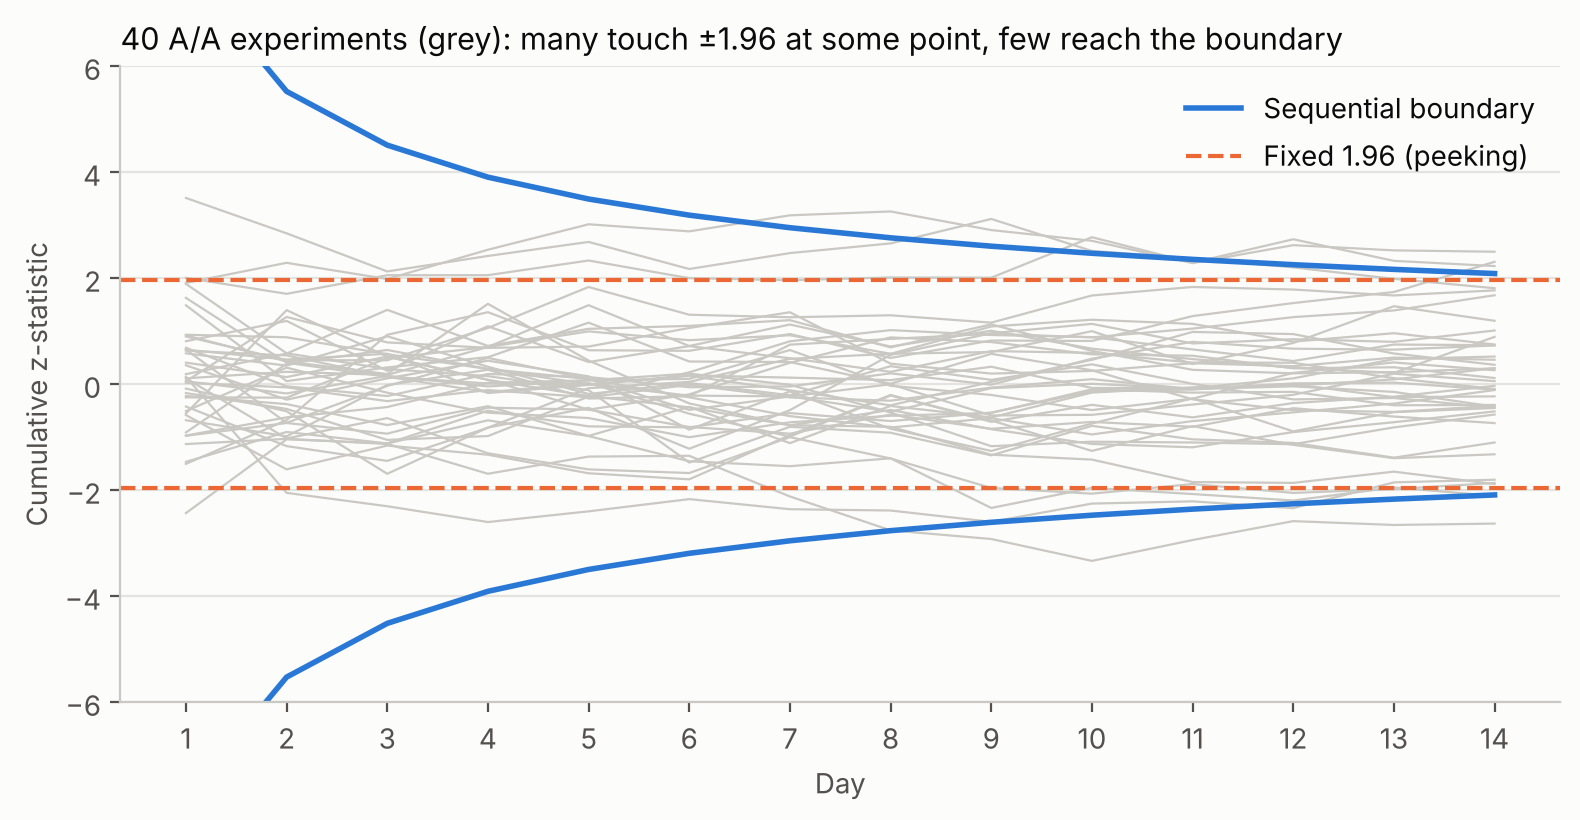

In [5]:
# figure: sequential_boundary
fig, ax = new_figure(8, 4.2)
for path in aa.z[:40]:
    ax.plot(days, path, color="#c9c8c3", linewidth=0.8)
ax.plot(days, bounds, color=SERIES[0], linewidth=2, label="Sequential boundary")
ax.plot(days, -bounds, color=SERIES[0], linewidth=2)
ax.axhline(Z, color=SERIES[1], linewidth=1.5, linestyle="--", label="Fixed 1.96 (peeking)")
ax.axhline(-Z, color=SERIES[1], linewidth=1.5, linestyle="--")
ax.set_xticks(days)
ax.set_ylim(-6, 6)
style_axes(ax, title="40 A/A experiments (grey): many touch ±1.96 at some point, few reach the boundary",
           xlabel="Day", ylabel="Cumulative z-statistic")
ax.legend(frameon=False, loc="upper right", labelcolor=INK)
plt.tight_layout()
plt.show()

In [6]:
sequential_aa = apply_rule(aa.z, lambda z: np.abs(z) > bounds)
print(f"False positives with daily looks and the sequential boundary: {sequential_aa.share_stopped:.1%}")

False positives with daily looks and the sequential boundary: 4.7%


Back to about 5%. The price is that a significant result needs stronger evidence early on. Does that cost the ability to detect real effects? Simulate a coupon with a true +5% relative lift in orders:

In [7]:
rows = []
for lift in [0.03, 0.05]:
    ab = simulate_daily_paths(P_CONTROL, P_CONTROL * (1 + lift), USERS_PER_DAY, DAYS, N_SIMS, seed=12)
    fixed = (np.abs(ab.z[:, -1]) > Z).mean()
    seq = apply_rule(ab.z, lambda z: np.abs(z) > bounds)
    rows.append({"true lift": lift, "power, one look at day 14": fixed, "power, sequential": seq.share_stopped,
                 "average stopping day, sequential": seq.mean_stop_day})
pd.DataFrame(rows).set_index("true lift").style.format({"power, one look at day 14": "{:.0%}", "power, sequential": "{:.0%}",
                                                        "average stopping day, sequential": "{:.1f}"}).format_index("{:+.0%}")

,"power, one look at day 14","power, sequential","average stopping day, sequential"
true lift,,,
+3%,57%,56%,12.0
+5%,95%,94%,9.0


Almost the same power as waiting for day 14, and when the effect is clear the test stops early (around day 9 for a +5% lift), which saves days of giving the worse experience to half the users. A sequential design gives the benefits people want from peeking without its cost.

## 4. Bayesian monitoring has the same problem

A popular alternative is to report the **probability that the treatment is better** (from a Bayesian model with flat priors) and stop when it passes 95%. As a summary of the evidence, that probability is perfectly reasonable. As a daily stopping rule:

In [8]:
bayes_peek = apply_rule(aa.prob_better, lambda p: p > 0.95)
print(f"A/A tests where 'P(better) > 95%' was reached on some day: {bayes_peek.share_stopped:.0%}")
print(f"Same rule, applied once at the end:                        {(aa.prob_better[:, -1] > 0.95).mean():.0%}")

A/A tests where 'P(better) > 95%' was reached on some day: 19%
Same rule, applied once at the end:                        5%


With flat priors and this much data, the probability of being better is essentially a transformed z-statistic, so a fixed 95% threshold checked daily behaves like peeking. Bayesian methods handle monitoring well when the decision rule accounts for it (for example informative priors, or rules based on the expected loss of a wrong decision), but simply swapping p-values for probabilities does not.

## 5. Rules for monitoring in practice

1. **Fix the analysis horizon in the design doc**, as in chapter 2, and read the result once.
2. **If you need to stop early, plan for it**: choose a sequential design and its boundaries before launch.
3. **Monitor validity and harm every day, but don't use the day's p-value to declare a winner.** Watch the sample ratio (chapter 3) and guardrail metrics with strict thresholds; stopping for a broken experiment or real harm is always allowed.
4. **Run A/A tests** when setting up an experimentation system, and after major changes to it.

## Try it yourself

**a)** Change the number of looks from 14 to 4 (weekly-ish). How much does peeking inflate false positives now? Recalibrate the boundary.

**b)** Pocock boundaries use the same threshold at every look. Find by simulation the constant threshold that gives a 5% false-positive rate with 14 looks, and compare its power and stopping day with O'Brien–Fleming.

**c)** A stakeholder sees p = 0.03 on day 3 and wants to stop. Using the boundary table, write the two-sentence answer.